<a href="https://colab.research.google.com/github/hyui02/ESAA_assignment/blob/main/ESAA_WEEK12_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##09 회귀 실습- 자전거 대여 수요 예측
1. 데이터 정리
- datetime: hourly date + timestamp
- season: 1=봄, 2=여름, 3= 가을, 4=겨울
- holiday: 1= 토,일요일의 주말을 제외한 국경일 등의 휴일. 0=휴일이 아닌 날
- workingday: 1=토,일요일의 주말 및 휴일이 아닌 주중, 0= 주말 및 휴일
- weather: 1= 맑음, 약간 구름 낀 흐림, 2= 안개, 안개+ 흐림, 3= 가벼운 눈. 가벼운 비+천둥, 4= 심한눈/비, 천둥/번개

- temp: 온도(섭씨)
- atemp: 체감온도(섭씨)
- humidity: 상대습도
- windspeed: 풍속
- casual: 사전에 등록되지 않느 사용자가 대여한 횟수
- registered: 사전에 등록된 사용자가 대여한 횟수
- count: 대여 횟수

###데이터 클렌징 및 가공과 데이터 시각화

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

bike_df=pd.read_csv('/content/train-2.csv')
print(bike_df.shape)
bike_df.head()

(10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [2]:
bike_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [3]:
#문자열을 datetime 타입으로 변경
bike_df['datetime']= bike_df.datetime.apply(pd.to_datetime)

#datetime 타입에서 년, 월,일 시간 추출
bike_df['year']=bike_df.datetime.apply(lambda x: x.year)
bike_df['month']=bike_df.datetime.apply(lambda x: x.month)
bike_df['day']=bike_df.datetime.apply(lambda x: x.day)
bike_df['hour']=bike_df.datetime.apply(lambda x: x.hour)
bike_df.head(3)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011,1,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011,1,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011,1,1,2


In [4]:
drop_columns= ['datetime', 'casual','registered']
bike_df.drop(drop_columns, axis=1, inplace=True)


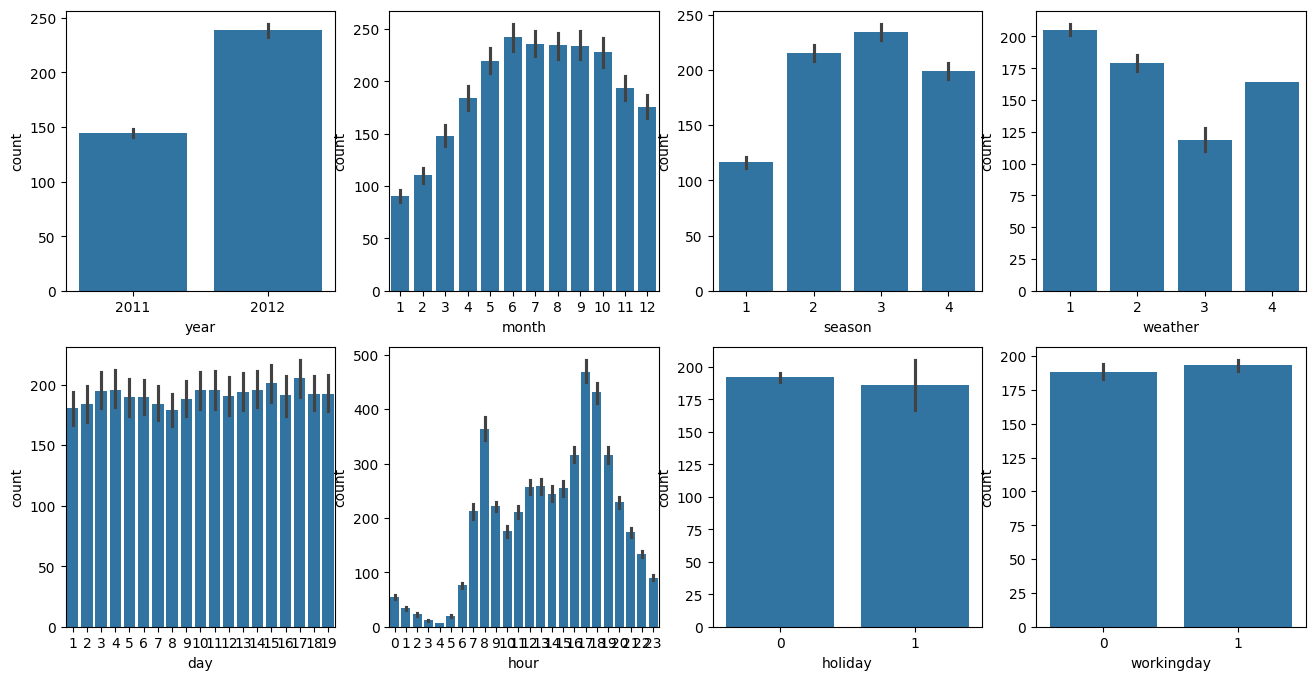

In [5]:
fig,axs= plt.subplots(figsize=(16,8),ncols=4, nrows=2)
cat_features= ['year','month','season','weather','day','hour','holiday','workingday']
#cat_features에 있는 모든 칼러별로 개별 칼럼값에 따른 count의 합을 barplot으로 시각화
for i, feature in enumerate(cat_features):
  row=int(i/4)
  col=i%4
  #시본의 barplot을 이용해 칼럼값에 따른 count의 합을 표현
  sns.barplot(x=feature, y='count', data=bike_df, ax=axs[row][col])

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

#log 값 변환 시 NaN 등의 이슈로 log()가 아닌 log1p()를 이용해 RMSLE 계산
def rmsle(y,pred):
  log_y=np.log1p(y)
  log_pred=np.log1p(pred)
  squared_error=(log_y-log_pred)**2
  rmsle=np.sqrt(np.mean(squared_error))
  return rmsle

#사이킷런의 mean_square_error()를 이용해 rmse 계산
def rmse(y,pred):
  return np.sqrt(mean_squared_error(y,pred))

#MAE, RMSE, RMSLE 모두 계산
def evaluate_regr (y,pred):
  rmsle_val=rmsle(y,pred)
  rmse_val=rmse(y,pred)
  #MAE는 사이킷런의 mean_absolute_error()로 계산
  mae_val=mean_absolute_error(y,pred)
  print('RMSLE:{0:3f},RMSE:{1:.3F},MAE:{2:3F}'.format(rmsle_val,rmse_val,mae_val))

- msle를 구할 때 넘파이의 log 함수를 이용하거나 사이킷런의 mean_squared_log_error()를 이용할 수도 있지만 데이터 값의 크기에 따라 오버플로/언더플로 오류가 발생하기 쉽다

- log() 보다는  log1p()를 이용하는데 log1p(x)의 경우는 log(1+x)로 변환되로 x값이 0이 되더라도 log(0)인 무한대가 되지 않고, log(1)인 0이 되므로 오버플로.언더플로 문제로 해결해준다. 그리고 log1p()로 변환된 값은 다시 넘파이의 expm1() 함수로 쉽게 원래의 스케일로 복왼될 수 있음

##로그변환, 피처 인코딩과 모델학습/예측/평가

In [7]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso

y_target=bike_df['count']
X_features=bike_df.drop(['count'], axis=1, inplace=False)

X_train,X_test,y_train,y_test=train_test_split(X_features,y_target,
                                               test_size=0.3, random_state=0)

lr_reg=LinearRegression()
lr_reg.fit(X_train,y_train)
pred=lr_reg.predict(X_test)
evaluate_regr(y_test,pred)

RMSLE:1.164664,RMSE:140.900,MAE:105.924448


In [8]:
def get_top_error_data(y_test,pred,n_tops=5):
  #DataFrame의 칼럼으로 실제 대여 횟수(count)와 예측값을 서로 비교할 수 있도록 생성
  result_df=pd.DataFrame(y_test.values, columns=['real_count'])
  result_df['predicted_count']=np.round(pred)
  result_df['diff']=np.abs(result_df['real_count']-result_df['predicted_count'])

#예측값과 실제값이 가장 큰 데이터 순으로 출력
  print(result_df.sort_values('diff',ascending=False)[:n_tops])

get_top_error_data(y_test,pred,n_tops=5)

      real_count  predicted_count   diff
1618         890            322.0  568.0
966          884            327.0  557.0
3151         798            241.0  557.0
412          745            194.0  551.0
2817         856            310.0  546.0


- 큰 예측 오류가 발생할 경우 가장 먼저 살펴볼 것은 Target 값의 분포가 왜곡된 형태를 이루고 있는지 확인한 것
-> Target값의 분포가 정규 분표 형태일 때 가장 좋음

<Axes: >

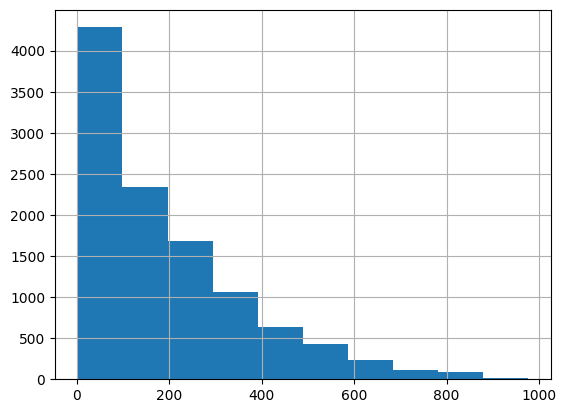

In [9]:
y_target.hist()

<Axes: >

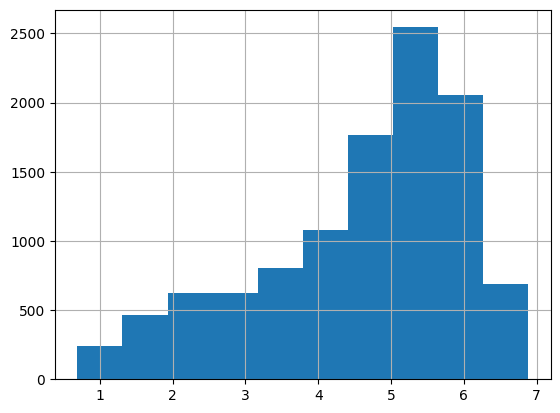

In [10]:
y_log_transform=np.log1p(y_target)
y_log_transform.hist()

In [11]:
#타깃 칼럼인 count 값을 log1p로 로그변환
y_target=np.log1p(y_target)

#로그변환된  y_target_log 를 반영해 학습/테스트 데이트 세트 분할
X_train,X_test,y_train,y_test=train_test_split(X_features,y_target,
                                               test_size=0.3, random_state=0)

lr_reg= LinearRegression()
lr_reg.fit(X_train,y_train)
pred=lr_reg.predict(X_test)

#테스트 데이터 세트의 target 값은 로그 변환됐으므로 다시 expm1을 이용해 원래 스케일로 변환
y_test_exp=np.expm1(y_test)

#예측값 역시 로그 변환된 타깃 기반으로 학습돼 예측됐으므로 다시 expm1로 스케일 변환
pred_exp=np.expm1(pred)

evaluate_regr(y_test_exp,pred_exp)

RMSLE:1.016827,RMSE:162.594,MAE:109.286159


<Axes: ylabel='None'>

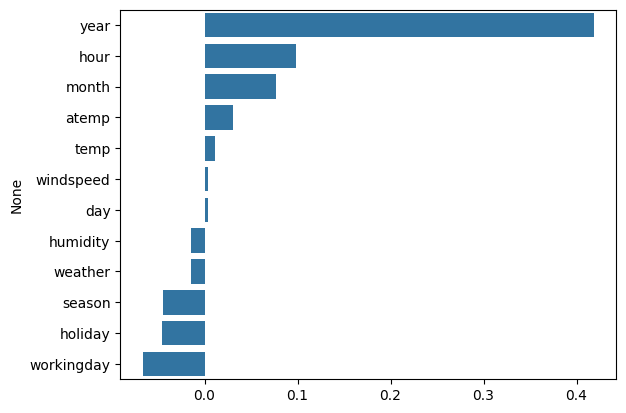

In [12]:
coef= pd.Series(lr_reg.coef_, index=X_features.columns)
coef_sort=coef.sort_values(ascending=False)
sns.barplot(x=coef_sort.values, y=coef_sort.index)

In [13]:
# 'year', 'month’, ‘day’, hour"등의 피처들을 One Hot Encoding
X_features_one_hot=pd.get_dummies(X_features, columns=['year','month','day','hour',
                                                       'holiday','workingday','season',
                                                       'weather',])

In [14]:
#원핫 인코딩이 적용된 피처 데이터 세트 기반으로 학습/예측 데이터 분할
X_train,X_test,y_train,y_test=train_test_split(X_features_one_hot,y_target,
                                               test_size=0.3, random_state=0)

#모델과 학습/테스트 데이터 세트를 입력하면 성능 평가 수치를 반환
def get_model_predict(model, X_train, X_test, y_train, y_test,is_expm1=False):
  model.fit(X_train,y_train)
  pred=model.predict(X_test)
  if is_expm1:
    y_test=np.expm1(y_test)
    pred=np.expm1(pred)
  print('###',model.__class__.__name__,'###')
  evaluate_regr(y_test,pred)

#end of function get_model_predict

#모델별로 평가 수행
lr_reg=LinearRegression()
ridge_reg=Ridge(alpha=10)
lasso_reg=Lasso(alpha=0.01)

for model in [lr_reg, ridge_reg, lasso_reg]:
  get_model_predict(model, X_train, X_test, y_train, y_test, is_expm1=True)

### LinearRegression ###
RMSLE:0.589634,RMSE:97.688,MAE:63.382029
### Ridge ###
RMSLE:0.590137,RMSE:98.529,MAE:63.893353
### Lasso ###
RMSLE:0.634752,RMSE:113.219,MAE:72.802707


<Axes: ylabel='None'>

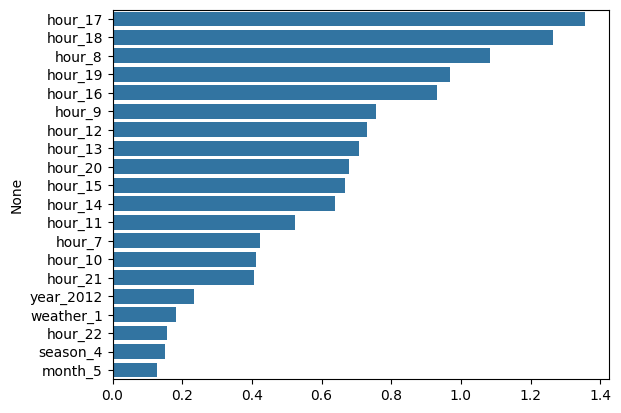

In [15]:
coef=pd.Series(lr_reg.coef_, index=X_features_one_hot.columns)
coef_sort=coef.sort_values(ascending=False)[:20]
sns.barplot(x=coef_sort.values, y=coef_sort.index)

In [16]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

#랜덤포레스트,GBM,XGBoost,LightGBM model 별로 평가 수행
rf_reg=RandomForestRegressor(n_estimators=500)
gbm_reg=GradientBoostingRegressor(n_estimators=500)
xgb_reg=XGBRegressor(n_estimators=500)
lgbm_reg=LGBMRegressor(n_estimators=500)

for model in [rf_reg, gbm_reg, xgb_reg, lgbm_reg]:
  #XGBoost의 경우 DataFrame이 입력된 경우 버전에 따라 오류 발생 가능. ndarray로 변환
  get_model_predict(model, X_train, X_test, y_train, y_test, is_expm1=True)

### RandomForestRegressor ###
RMSLE:0.354246,RMSE:50.431,MAE:31.195966
### GradientBoostingRegressor ###
RMSLE:0.329799,RMSE:53.336,MAE:32.737676
### XGBRegressor ###
RMSLE:0.338795,RMSE:51.475,MAE:31.356583
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000471 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 348
[LightGBM] [Info] Number of data points in the train set: 7620, number of used features: 72
[LightGBM] [Info] Start training from score 4.582043
### LGBMRegressor ###
RMSLE:0.318846,RMSE:47.215,MAE:29.028770


#10. 회귀 실습- 캐글 주택 가격: 고급 회귀 기법
##데이터 사전 처리

In [17]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

house_df_org = pd.read_csv('/content/train-3.csv')
house_df = house_df_org.copy()
house_df.head(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [18]:
print('데이터 세트의 shape:',house_df.shape)
print('\n 전체 피처의 type\n', house_df.dtypes.value_counts())
isnull_series=house_df.isnull().sum()
print('\nNull 칼럼과 그 건수:\n',isnull_series[isnull_series > 0].sort_values(ascending=False))

데이터 세트의 shape: (1460, 81)

 전체 피처의 type
 object     43
int64      35
float64     3
Name: count, dtype: int64

Null 칼럼과 그 건수:
 PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


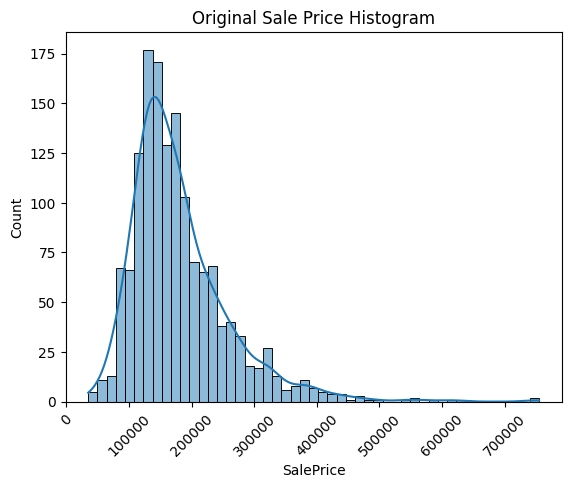

In [19]:
plt.title('Original Sale Price Histogram')
plt.xticks(rotation=45)
sns.histplot(house_df['SalePrice'],kde=True)
plt.show()

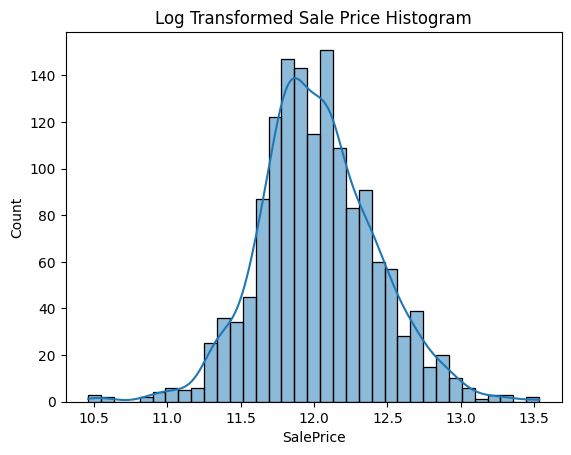

In [20]:
plt.title('Log Transformed Sale Price Histogram')
log_price=np.log1p(house_df['SalePrice'])
sns.histplot(log_price,kde=True)
plt.show()

In [21]:
# SalePrice 로그 변환
original_SalePrice = house_df['SalePrice']
house_df['SalePrice'] = np.log1p(house_df['SalePrice'])


# Null이 너무 많은 칼럼과 불필요한 칼럼 삭제
house_df.drop(['Id', 'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu'],axis=1, inplace=True)

# 드롭하지 않은 숫자형 Null 칼럼은 평균값으로 대체
numerical_cols = house_df.select_dtypes(include=np.number).columns
house_df[numerical_cols] = house_df[numerical_cols].fillna(house_df[numerical_cols].mean())



# Null 값이 있는 피처명과 타입을 추출
null_column_count = house_df.isnull().sum()[house_df.isnull().sum() >0]
print('## Null 피처의 Type: \n', house_df.dtypes[null_column_count.index])

## Null 피처의 Type: 
 MasVnrType      object
BsmtQual        object
BsmtCond        object
BsmtExposure    object
BsmtFinType1    object
BsmtFinType2    object
Electrical      object
GarageType      object
GarageFinish    object
GarageQual      object
GarageCond      object
dtype: object


In [22]:
print('get_dummoes()수행 전 데이터 Shape:', house_df.shape)
house_df_ohe= pd.get_dummies(house_df)
print('get_dummies() 수행 후 데이터 Shape:', house_df_ohe.shape)

null_column_count=house_df_ohe.isnull().sum()[house_df_ohe.isnull().sum() > 0]
print('## Null 피처의 Type: \n', house_df_ohe.dtypes[null_column_count.index])

get_dummoes()수행 전 데이터 Shape: (1460, 75)
get_dummies() 수행 후 데이터 Shape: (1460, 270)
## Null 피처의 Type: 
 Series([], dtype: object)


#선형 회귀모델 학습/예측/평가


In [23]:
def get_rmse(model):
  pred=model.predict(X_test)
  mse=mean_squared_error(y_test,pred)
  rmse=np.sqrt(mse)
  print(model.__class__.__name__,'로그 변환된 RMSE',np.round(rmse,3))
  return rmse

def get_rmses(models):
  rmses=[]
  for model in models:
    rmse=get_rmse(model)
    rmses.append(rmse)
  return rmses

In [24]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

y_target=house_df_ohe['SalePrice']
X_features=house_df_ohe.drop(['SalePrice'], axis=1, inplace=False)

X_train,X_test,y_train,y_test=train_test_split(X_features,y_target, test_size=0.2, random_state=156)

#LinearRegression, Ridge, Lasso 학습 예측 평가
lr_reg=LinearRegression()
lr_reg.fit(X_train,y_train)
ridge_reg=Ridge()
ridge_reg.fit(X_train,y_train)
lasso_reg=Lasso()
lasso_reg.fit(X_train,y_train)

models=[lr_reg,ridge_reg,lasso_reg]
get_rmses(models)

LinearRegression 로그 변환된 RMSE 0.132
Ridge 로그 변환된 RMSE 0.127
Lasso 로그 변환된 RMSE 0.176


[np.float64(0.13183184688250701),
 np.float64(0.1274058283626616),
 np.float64(0.17628250556471403)]

In [25]:
def get_top_bottom_coef(model, n=10):
  # coef_ 속성을 기반으로 Series 객체를 생성,index는 칼럼명
  coef = pd.Series(model.coef_,index=X_features.columns)
  # + 상위 10개, -하위 10개의 회귀 계수를 추출해 반환.
  coef_high = coef.sort_values(ascending=False).head(n)
  coef_low = coef.sort_values(ascending=False).tail(n)
  return coef_high, coef_low

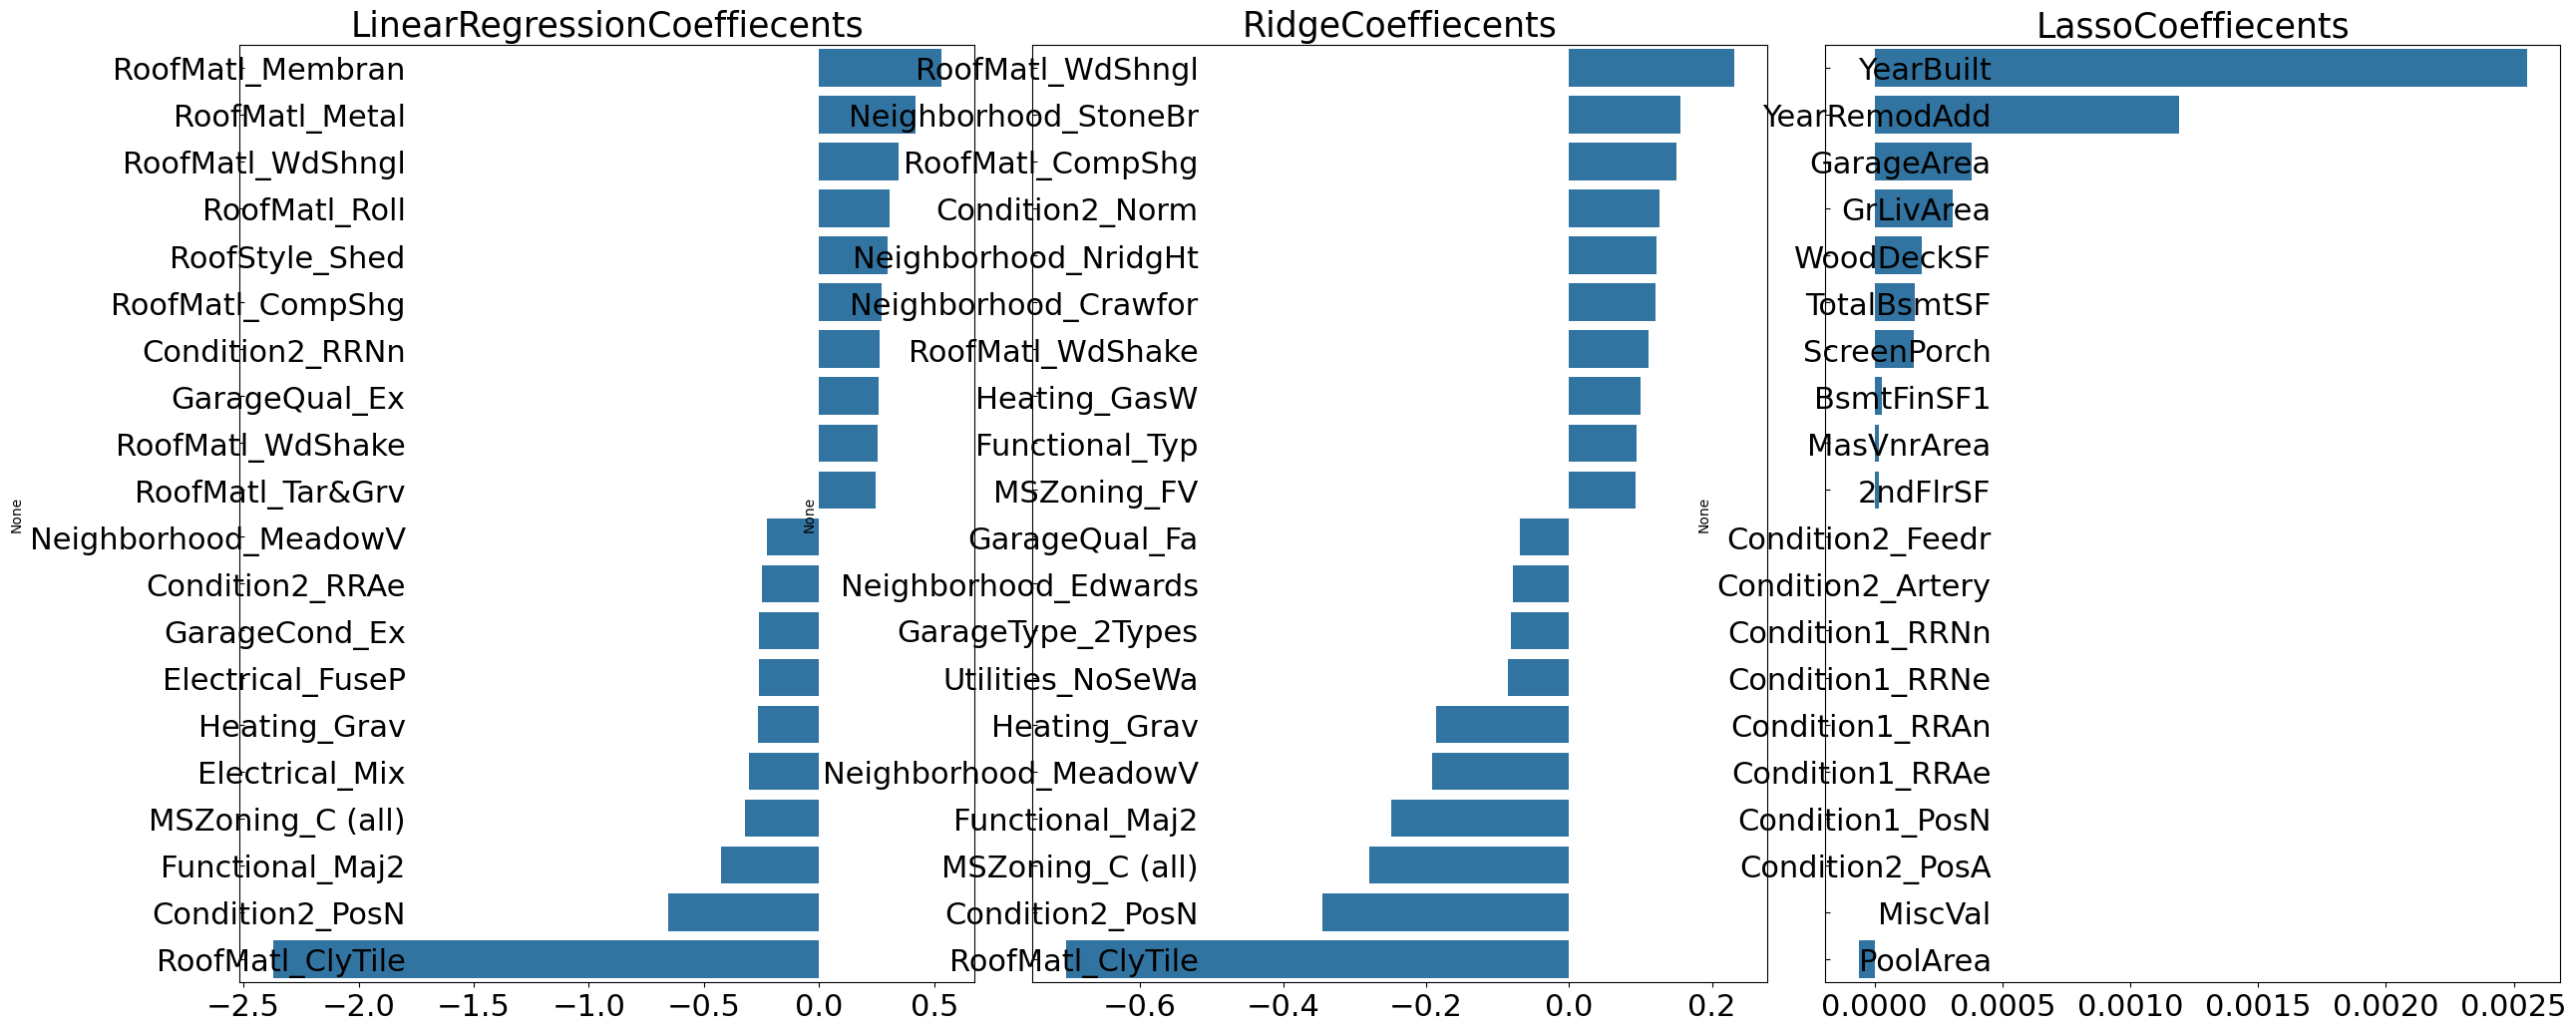

In [26]:
def visualize_coefficient(models):
  # 3개 회귀 모델의 시각화를 위해 3개의 칼럼을 가지는 subplot 생성
  fig, axs = plt.subplots(figsize=(24, 10), nrows=1, ncols=3)
  fig.tight_layout()
  # 입력 인자로 받은 list 객체인 models에서 차례로 model을 추출해 회귀 계수 시각화.
  for i_num, model in enumerate(models):
    # 상위 10개,하위 10개 회귀 계수를 구하고,이를 판다스 concat으로 결합
    coef_high, coef_low = get_top_bottom_coef(model)
    coef_concat = pd.concat( [coef_high, coef_low] )
    # ax subplot에 barchar로 표현.한 화면에 표현하기 위해 tick label 위치와 font 크기 조정.
    axs[i_num].set_title(model.__class__.__name__+ 'Coeffiecents', size=25)
    axs[i_num].tick_params(axis="y", direction="in", pad=-120)
    for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
      label.set_fontsize(22)
    sns.barplot(x=coef_concat.values, y=coef_concat.index, ax=axs[i_num])
# 앞 예제에서 학습한 lr_reg, ridge_reg, lasso_reg 모델의 회귀 계수 시각화
models= [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

In [27]:
from sklearn.model_selection import cross_val_score

def get_avg_rmse_cv(models):

  for model in models:
    #분할하지 않고 전체 데이터로 cross_val_score () 수행. 모델별 cv rmse값과 평균 rmse 출력
    rmse_list= np.sqrt(-cross_val_score(model, X_features, y_target,
                                        scoring='neg_mean_squared_error', cv=5))
    rmse_avg=np.mean(rmse_list)
    print('\n{0} CV RMSE 값리스트:{1}'.format(model.__class__.__name__, np.round(rmse_list,3)))
    print('{0} CV 평균 RMSE:{1}'.format(model.__class__.__name__, np.round(rmse_avg,3)))

#앞 예제에서 학습한 ridge_reg, lasso_reg 모델의 CV RMSE값 출력
models=[ridge_reg, lasso_reg]
get_avg_rmse_cv(models)


Ridge CV RMSE 값리스트:[0.117 0.154 0.142 0.117 0.189]
Ridge CV 평균 RMSE:0.144

Lasso CV RMSE 값리스트:[0.161 0.204 0.177 0.181 0.265]
Lasso CV 평균 RMSE:0.198


- Ridge와 Lasso 모두 5개 폴드의 RMSE가 들쭉날쭉하고, Lasso의 평균 RMSE가 Ridge보다 확실히 높음
-> 기본 alpha 값 그대로 쓰지 말고 모델별로 최적의 alpha를 찾아서 다시 학습시켜 볼 필요가 있음

##하이퍼 파라미터 튜닝
- GridSearchCV로 alpha 후보값들을 넣어 5폴드 교차 검증을 하고, 가장 RMSE가 낮은 alpha를 찾음
- 최적 파라미터, 최저 RMSE를 출력하고 최적 alpha로 학습된 모델(best_estimator_)을 반환하도록 함수로 만들어 두면 뒤에서 계속 재사용 가능

In [28]:
from sklearn.model_selection import GridSearchCV

def print_best_params(model, params):
  grid_model = GridSearchCV(model, param_grid=params,
                            scoring='neg_mean_squared_error', cv=5)
  grid_model.fit(X_features, y_target)
  rmse = np.sqrt(-1 * grid_model.best_score_)
  print('{0} 5 CV 시 최적 평균 RMSE 값: {1}, 최적 alpha:{2}'.format(model.__class__.__name__,
                                                          np.round(rmse, 4), grid_model.best_params_))
  return grid_model.best_estimator_

ridge_params = {'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20]}
lasso_params = {'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1, 5, 10]}
best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값: 0.1418, 최적 alpha:{'alpha': 12}
Lasso 5 CV 시 최적 평균 RMSE 값: 0.142, 최적 alpha:{'alpha': 0.001}


LinearRegression 로그 변환된 RMSE 0.132
Ridge 로그 변환된 RMSE 0.124
Lasso 로그 변환된 RMSE 0.12


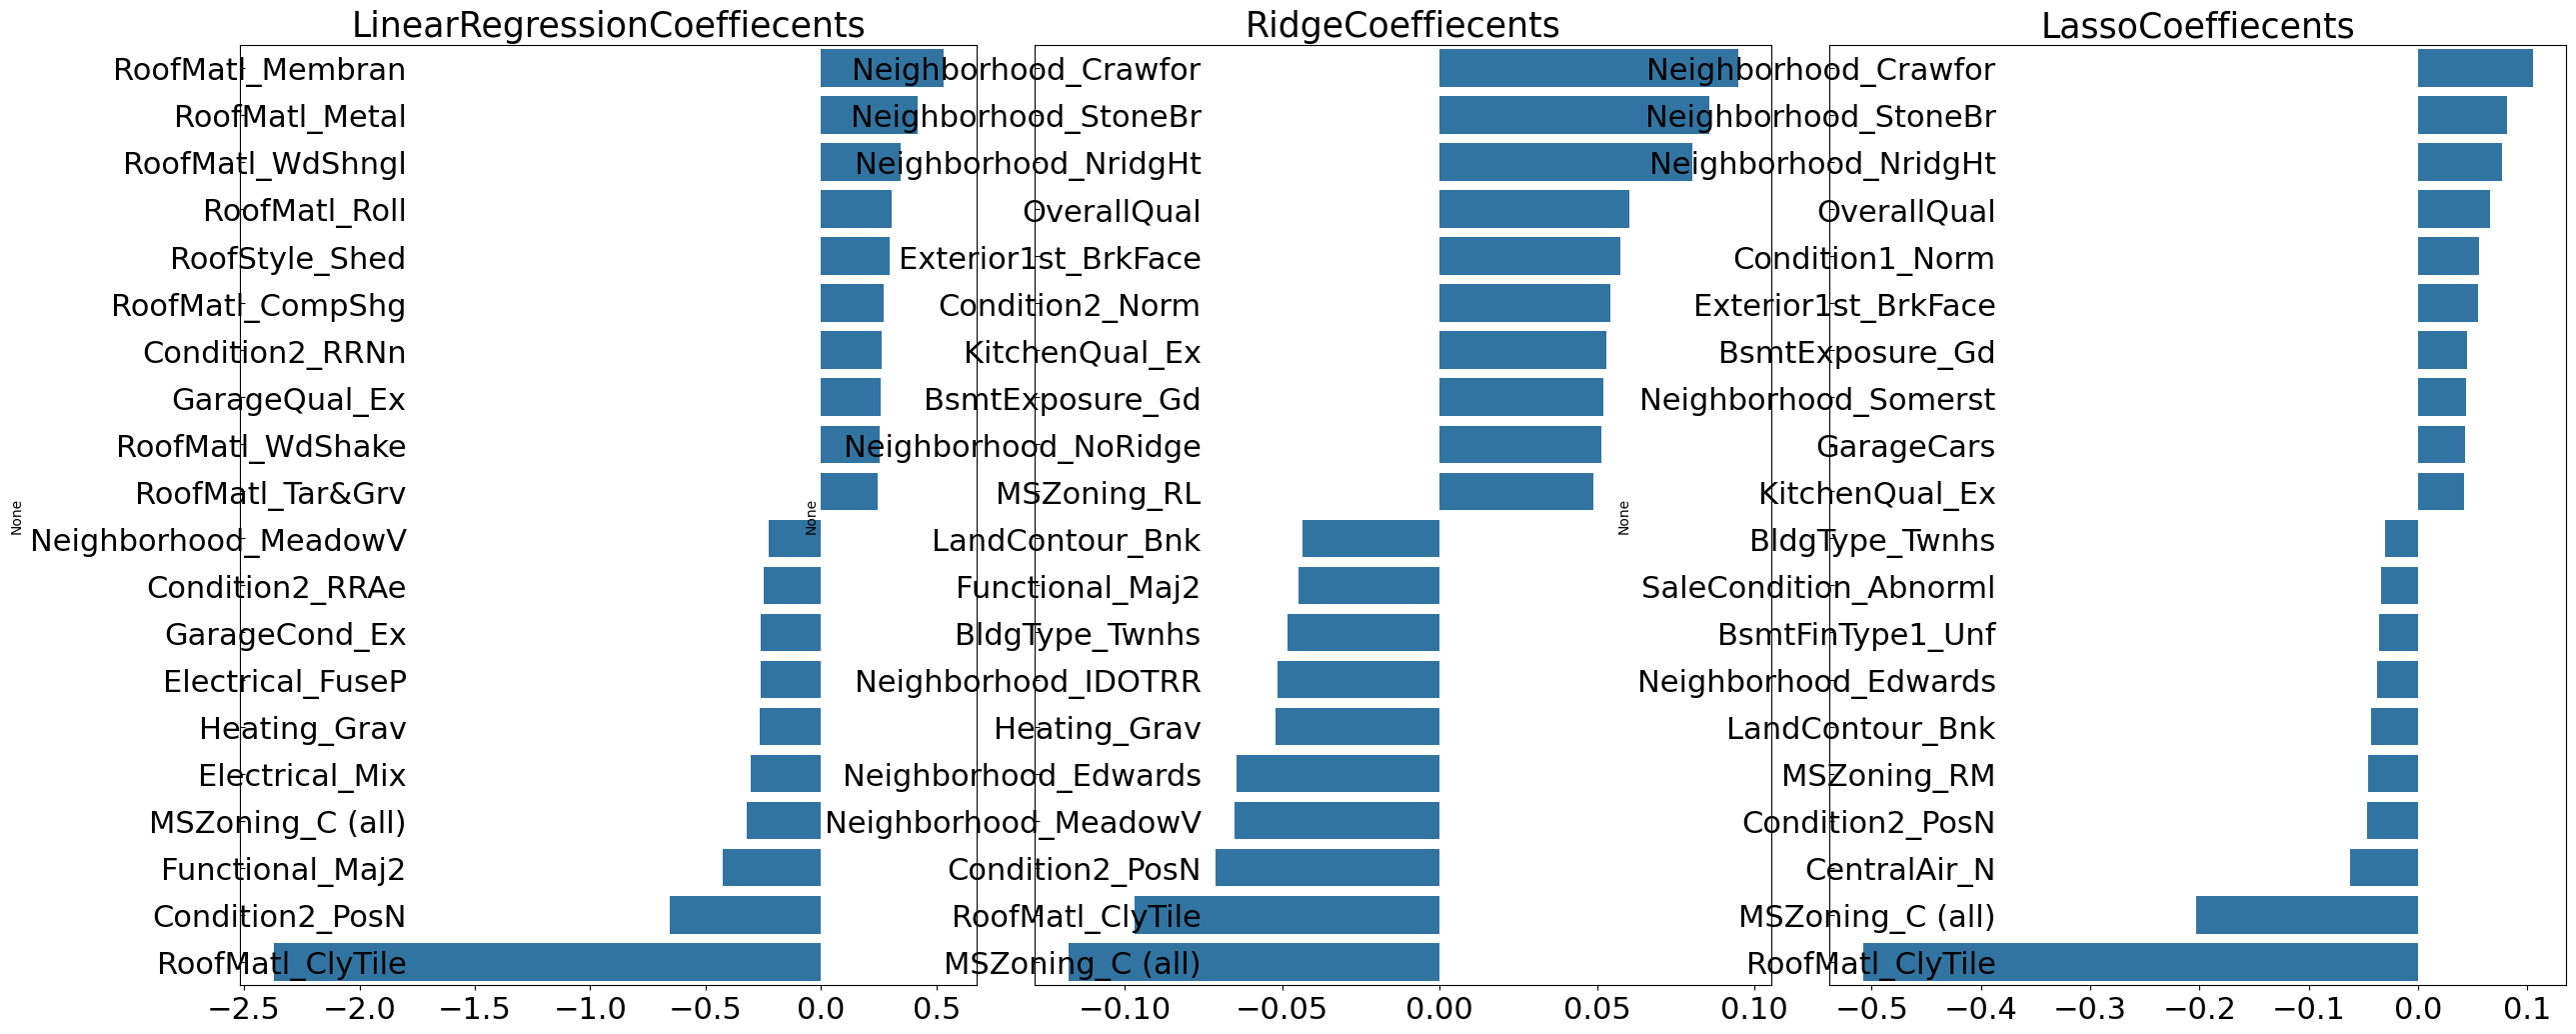

In [29]:
# 앞의 최적화 alpha 값으로 학습 데이터로 학습, 테스트 데이터로 예측 및 평가 수행
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=12)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

- alpha를 최적화하고 나니 Lasso의 RMSE가 크게 내려가서 Ridge와 비슷한 수준이 됨
- 다만 두 모델의 회귀 계수 상위/하위 피처 구성은 여전히 다름 -> 데이터 자체를 더 다듬어 볼 여지가 있음

##피처 데이터 세트의 왜곡도 조정
- 타깃값(SalePrice)뿐 아니라 피처 데이터도 한쪽으로 치우친 분포면 선형 회귀 성능에 악영향
- scipy의 skew()로 숫자형 피처의 왜곡 정도를 확인하고, 왜곡도가 1 이상인 피처만 log1p로 로그 변환
- 원핫 인코딩된 0/1 피처는 왜곡도를 따지는 게 의미가 없으므로, get_dummies() 전의 house_df에서 숫자형 피처만 골라서 확인해야 함

In [30]:
from scipy.stats import skew

# 숫자형 피처의 칼럼 index 객체 추출 (위에서 Null 채울 때와 같은 방식)
features_index = house_df.select_dtypes(include=np.number).columns
# house_df에 칼럼 index를 [ ]로 입력하면 해당하는 칼럼 데이터 세트 반환. apply lambda로 skew() 호출
skew_features = house_df[features_index].apply(lambda x : skew(x))
# skew(왜곡) 정도가 1 이상인 칼럼만 추출
skew_features_top = skew_features[skew_features > 1]
print(skew_features_top.sort_values(ascending=False))

MiscVal          24.451640
PoolArea         14.813135
LotArea          12.195142
3SsnPorch        10.293752
LowQualFinSF      9.002080
KitchenAbvGr      4.483784
BsmtFinSF2        4.250888
ScreenPorch       4.117977
BsmtHalfBath      4.099186
EnclosedPorch     3.086696
MasVnrArea        2.673661
LotFrontage       2.382499
OpenPorchSF       2.361912
BsmtFinSF1        1.683771
WoodDeckSF        1.539792
TotalBsmtSF       1.522688
MSSubClass        1.406210
1stFlrSF          1.375342
GrLivArea         1.365156
dtype: float64


In [31]:
# 왜곡도가 1 이상인 피처들을 로그 변환
house_df[skew_features_top.index] = np.log1p(house_df[skew_features_top.index])

In [32]:
# 왜곡도가 높은 피처를 로그 변환했으므로 다시 원핫 인코딩을 적용하고 피처/타깃 데이터 세트 생성
house_df_ohe = pd.get_dummies(house_df)
y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2, random_state=156)

# 피처를 로그 변환 후 다시 최적 하이퍼 파라미터와 RMSE 출력
ridge_params = {'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20]}
lasso_params = {'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1, 5, 10]}
best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값: 0.1275, 최적 alpha:{'alpha': 10}
Lasso 5 CV 시 최적 평균 RMSE 값: 0.1252, 최적 alpha:{'alpha': 0.001}


LinearRegression 로그 변환된 RMSE 0.128
Ridge 로그 변환된 RMSE 0.122
Lasso 로그 변환된 RMSE 0.119


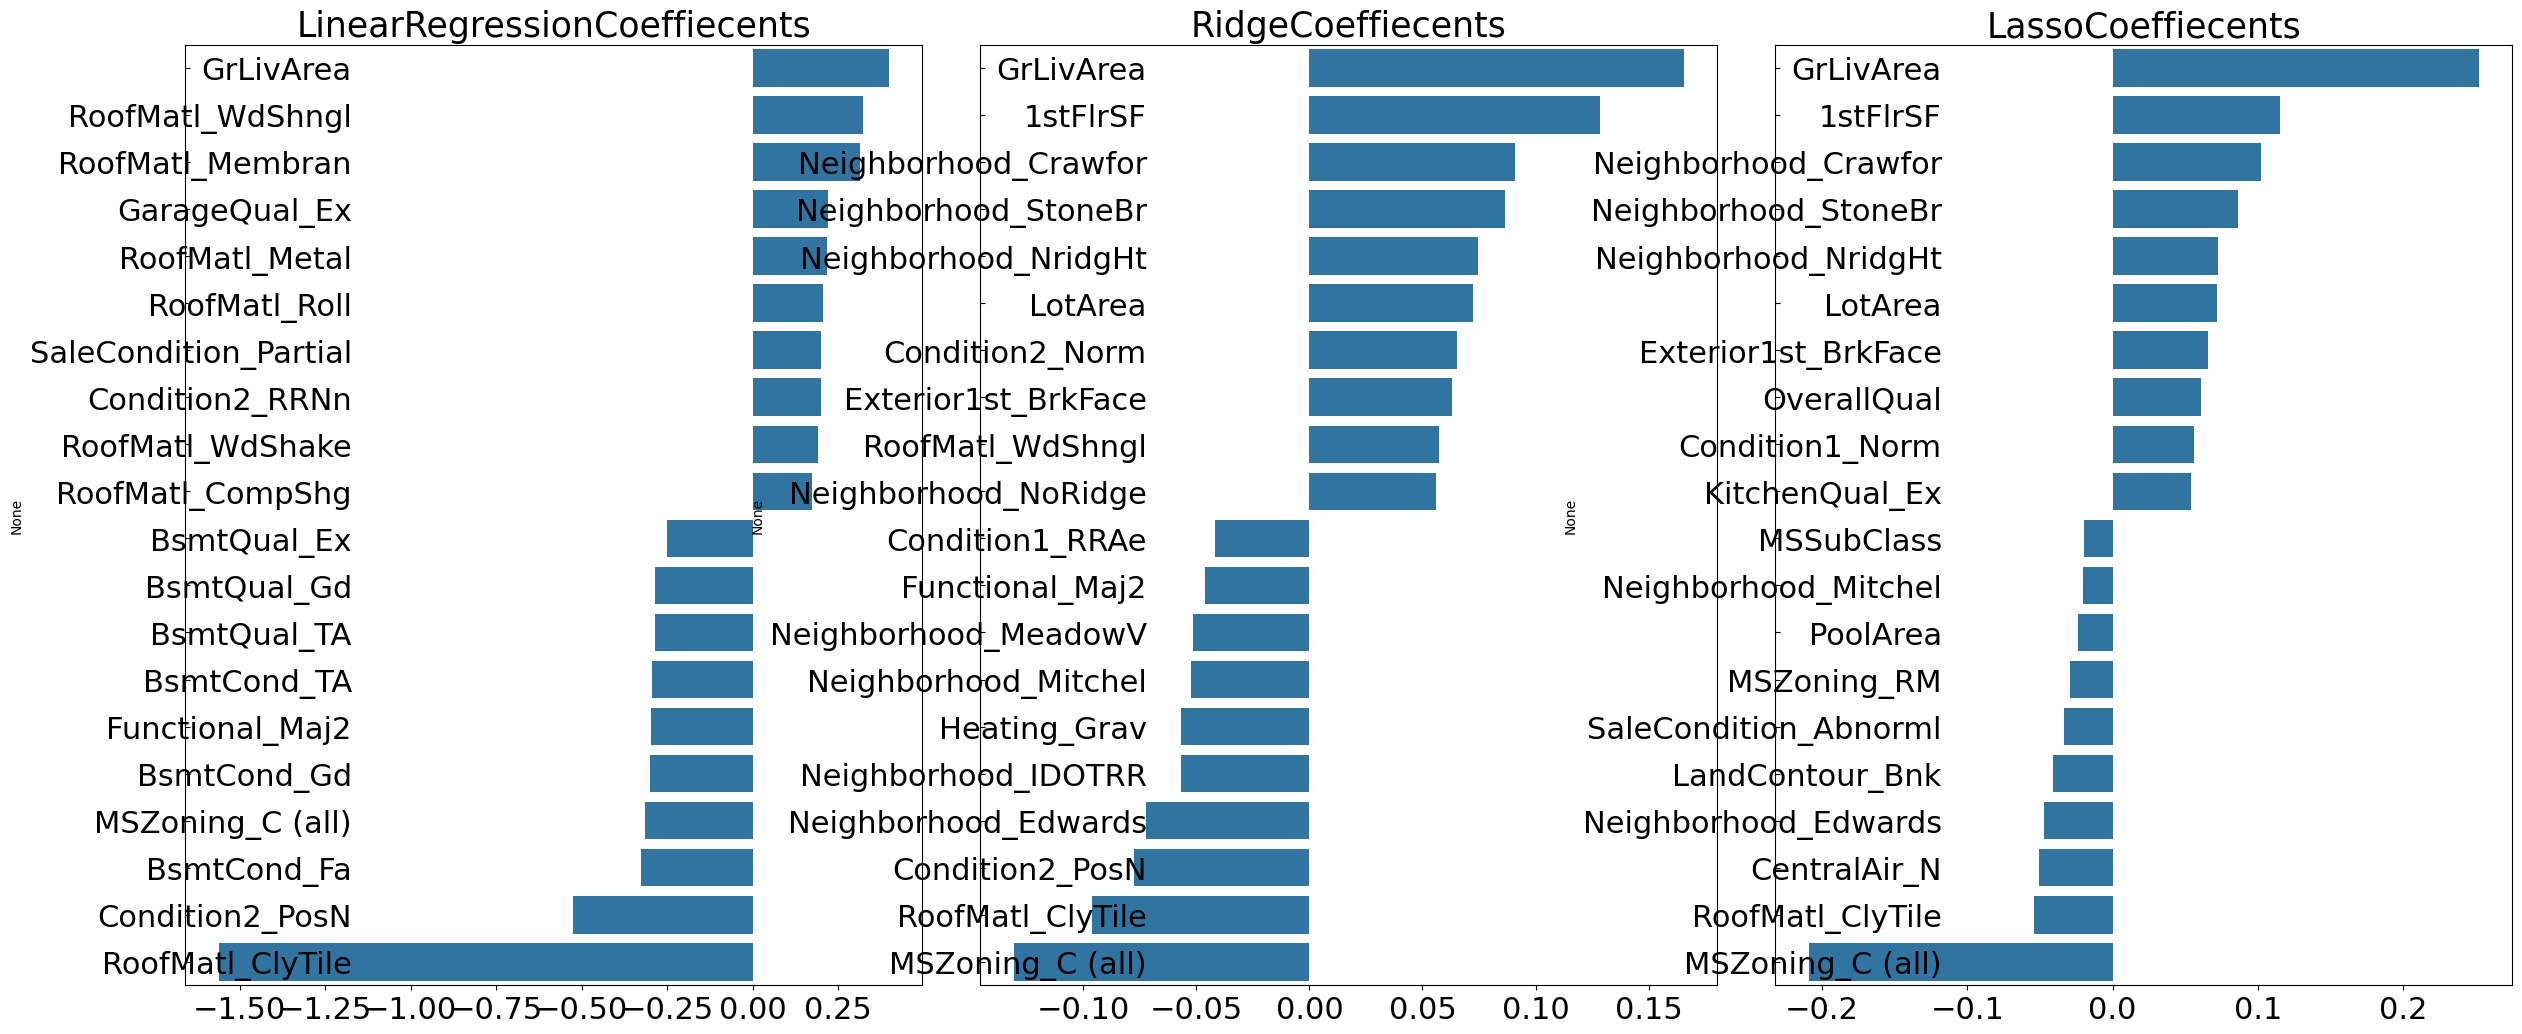

In [33]:
# 앞의 최적화 alpha 값으로 학습 데이터로 학습, 테스트 데이터로 예측 및 평가 수행
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=10)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

- 피처 로그 변환 후 세 모델 모두 RMSE가 조금씩 개선됨
- 세 모델 모두 GrLivArea(지상 생활 면적)의 회귀 계수가 상위권에 있음 -> 주택 가격에 큰 영향을 주는 피처이므로 이 피처의 데이터 분포를 따로 살펴볼 필요가 있음

##이상치 데이터 처리
- 회귀 계수가 높은 중요 피처에 이상치가 있으면 모델 전체 성능에 큰 영향을 줌
- 원본 데이터(house_df_org)로 GrLivArea와 SalePrice의 관계를 산점도로 확인

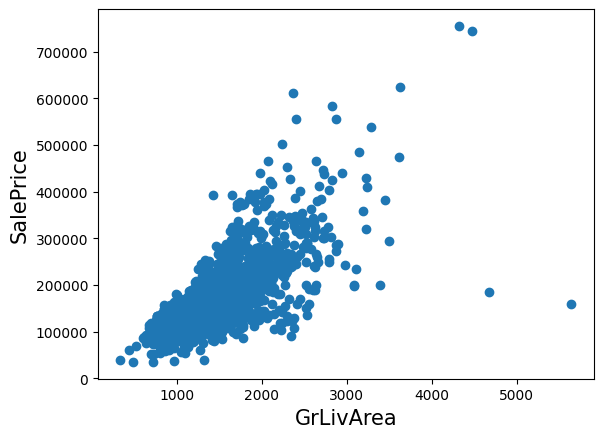

In [34]:
plt.scatter(x = house_df_org['GrLivArea'], y = house_df_org['SalePrice'])
plt.ylabel('SalePrice', fontsize=15)
plt.xlabel('GrLivArea', fontsize=15)
plt.show()

- 전체적으로 면적이 클수록 가격도 오르는 양의 관계인데, 오른쪽 아래에 면적은 4000 이상으로 매우 넓은데 가격은 50만 달러 이하로 낮은 데이터 2건이 있음 -> 이상치로 보고 삭제
- 이미 house_df_ohe의 GrLivArea와 SalePrice는 로그 변환된 상태이므로, 조건값(4000, 500000)도 log1p로 변환해서 비교해야 함

In [35]:
# GrLivArea와 SalePrice 모두 로그 변환됐으므로 이를 반영한 조건 생성
cond1 = house_df_ohe['GrLivArea'] > np.log1p(4000)
cond2 = house_df_ohe['SalePrice'] < np.log1p(500000)
outlier_index = house_df_ohe[cond1 & cond2].index

print('아웃라이어 레코드 index :', outlier_index.values)
print('아웃라이어 삭제 전 house_df_ohe shape:', house_df_ohe.shape)
# DataFrame의 인덱스를 이용해 아웃라이어 레코드 삭제
house_df_ohe.drop(outlier_index, axis=0, inplace=True)
print('아웃라이어 삭제 후 house_df_ohe shape:', house_df_ohe.shape)

아웃라이어 레코드 index : [ 523 1298]
아웃라이어 삭제 전 house_df_ohe shape: (1460, 270)
아웃라이어 삭제 후 house_df_ohe shape: (1458, 270)


In [36]:
# 이상치를 삭제한 데이터로 피처/타깃 데이터 세트를 다시 만들고 최적 하이퍼 파라미터 확인
y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2, random_state=156)

ridge_params = {'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20]}
lasso_params = {'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1, 5, 10]}
best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값: 0.1125, 최적 alpha:{'alpha': 8}
Lasso 5 CV 시 최적 평균 RMSE 값: 0.1122, 최적 alpha:{'alpha': 0.001}


LinearRegression 로그 변환된 RMSE 0.129
Ridge 로그 변환된 RMSE 0.103
Lasso 로그 변환된 RMSE 0.1


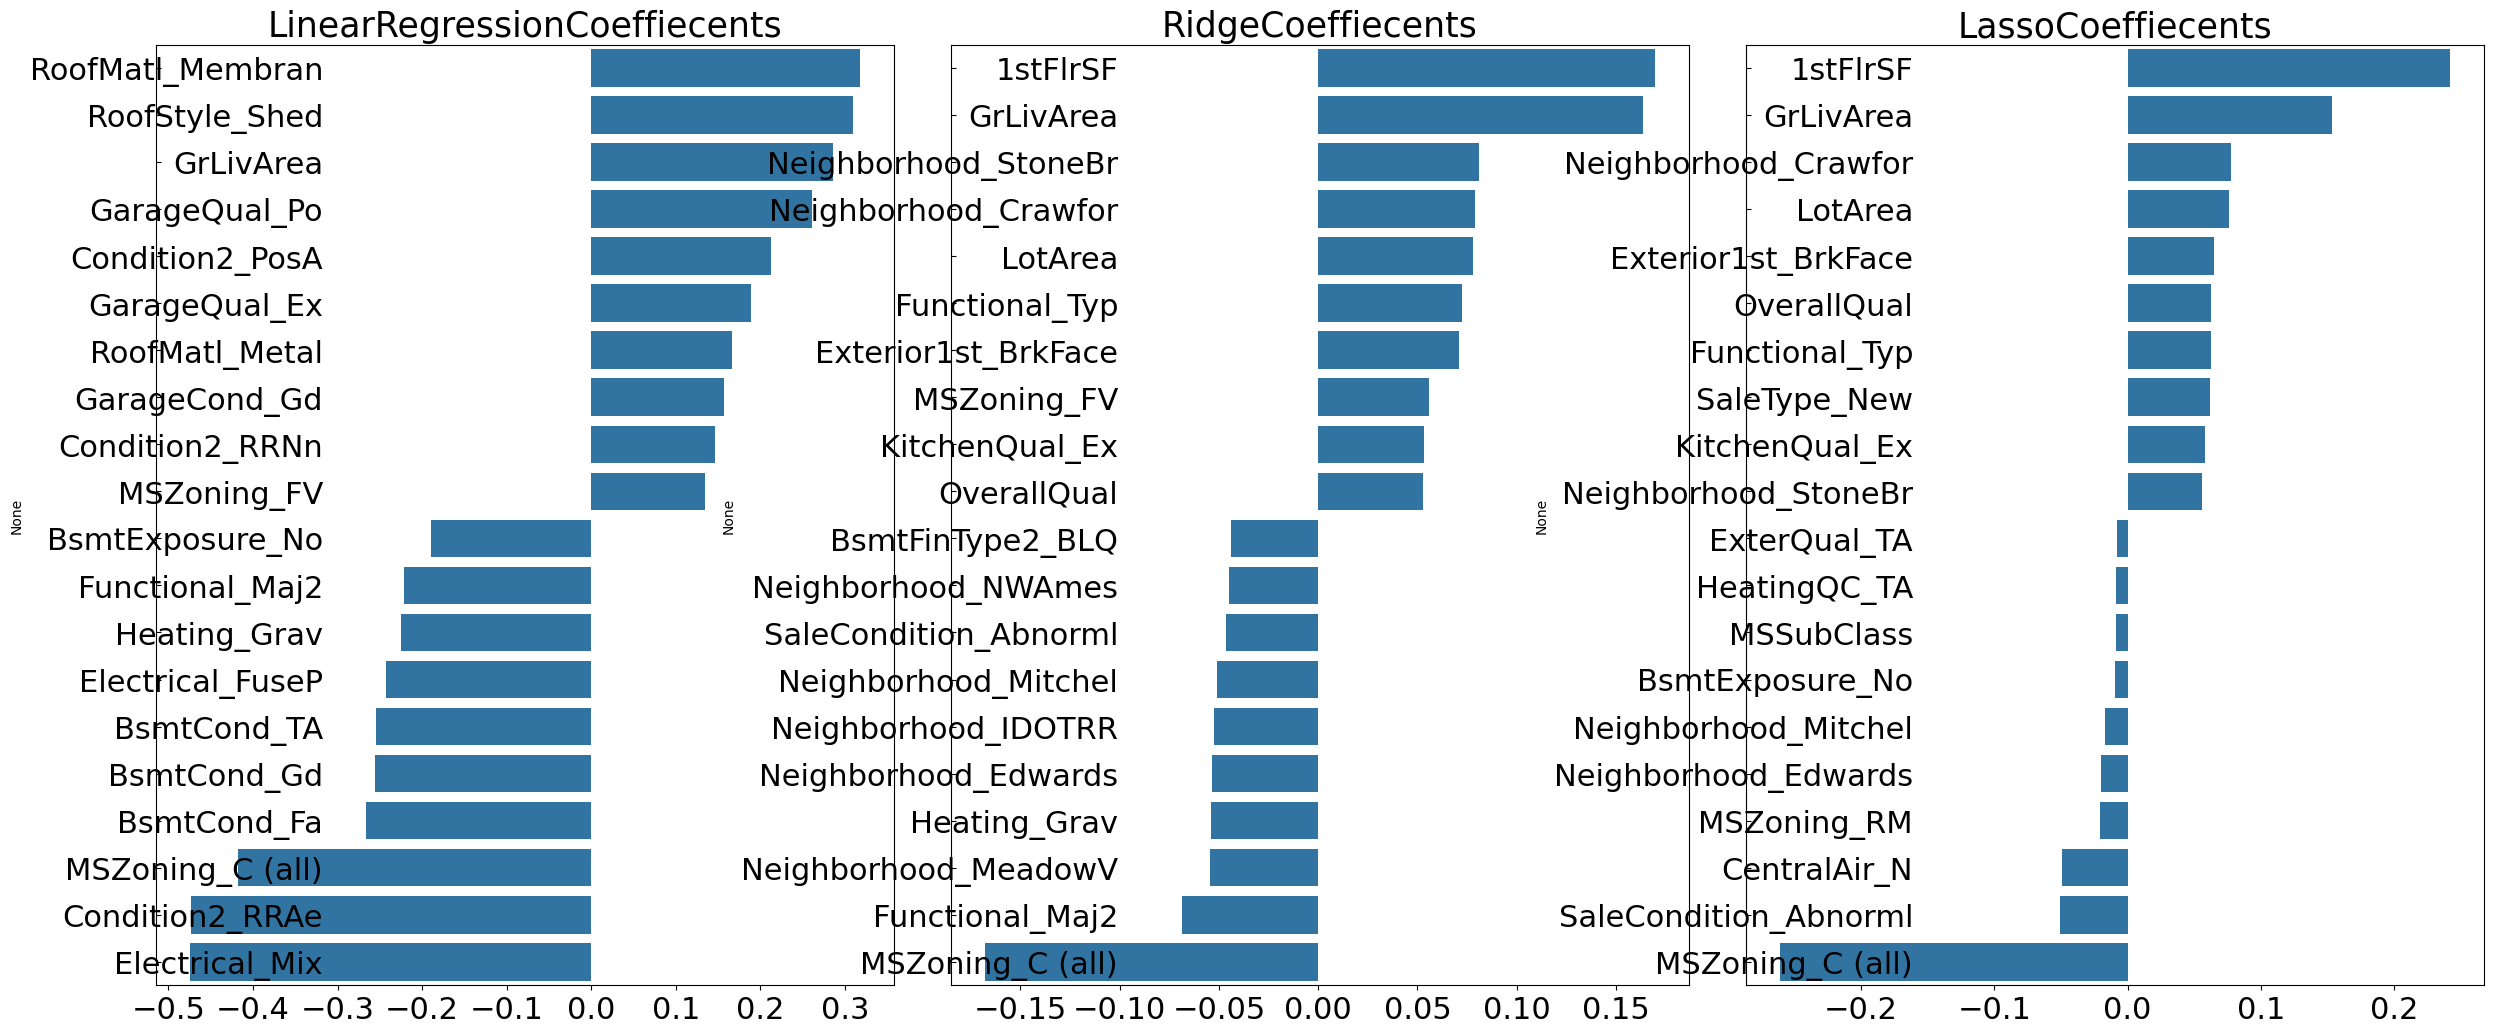

In [37]:
# 앞의 최적화 alpha 값으로 학습 데이터로 학습, 테스트 데이터로 예측 및 평가 수행
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

- 이상치 2건만 지웠는데도 Ridge, Lasso 모두 교차 검증 RMSE와 테스트 RMSE가 눈에 띄게 낮아짐
-> 머신러닝 프로세스 중에서 데이터의 가공은 알고리즘 적용 이전에 수행되는 중요한 작업이고, 중요 피처의 이상치 처리는 특히 신경 써야 함

#회귀 트리 모델 학습/예측/평가
- 이번에는 XGBoost와 LightGBM 회귀 트리 모델로 학습/예측/평가 진행
- 앞에서 만든 print_best_params()를 그대로 이용해 5폴드 교차 검증 평균 RMSE 확인
- 수행 시간이 오래 걸리므로 하이퍼 파라미터 후보는 n_estimators 하나만 넣고 나머지는 미리 정해둔 값으로 설정

In [38]:
from xgboost import XGBRegressor

xgb_params = {'n_estimators':[1000]}
xgb_reg = XGBRegressor(n_estimators=1000, learning_rate=0.05,
                       colsample_bytree=0.5, subsample=0.8)
best_xgb = print_best_params(xgb_reg, xgb_params)

XGBRegressor 5 CV 시 최적 평균 RMSE 값: 0.1205, 최적 alpha:{'n_estimators': 1000}


In [39]:
from lightgbm import LGBMRegressor

lgbm_params = {'n_estimators':[1000]}
lgbm_reg = LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=4,
                         subsample=0.6, colsample_bytree=0.4, reg_lambda=10, n_jobs=-1, verbose=-1)
best_lgbm = print_best_params(lgbm_reg, lgbm_params)

LGBMRegressor 5 CV 시 최적 평균 RMSE 값: 0.1179, 최적 alpha:{'n_estimators': 1000}


- 트리 모델은 회귀 계수(coef_) 대신 feature_importances_로 피처 중요도를 확인
- 두 모델의 피처 중요도 상위 20개를 나란히 시각화

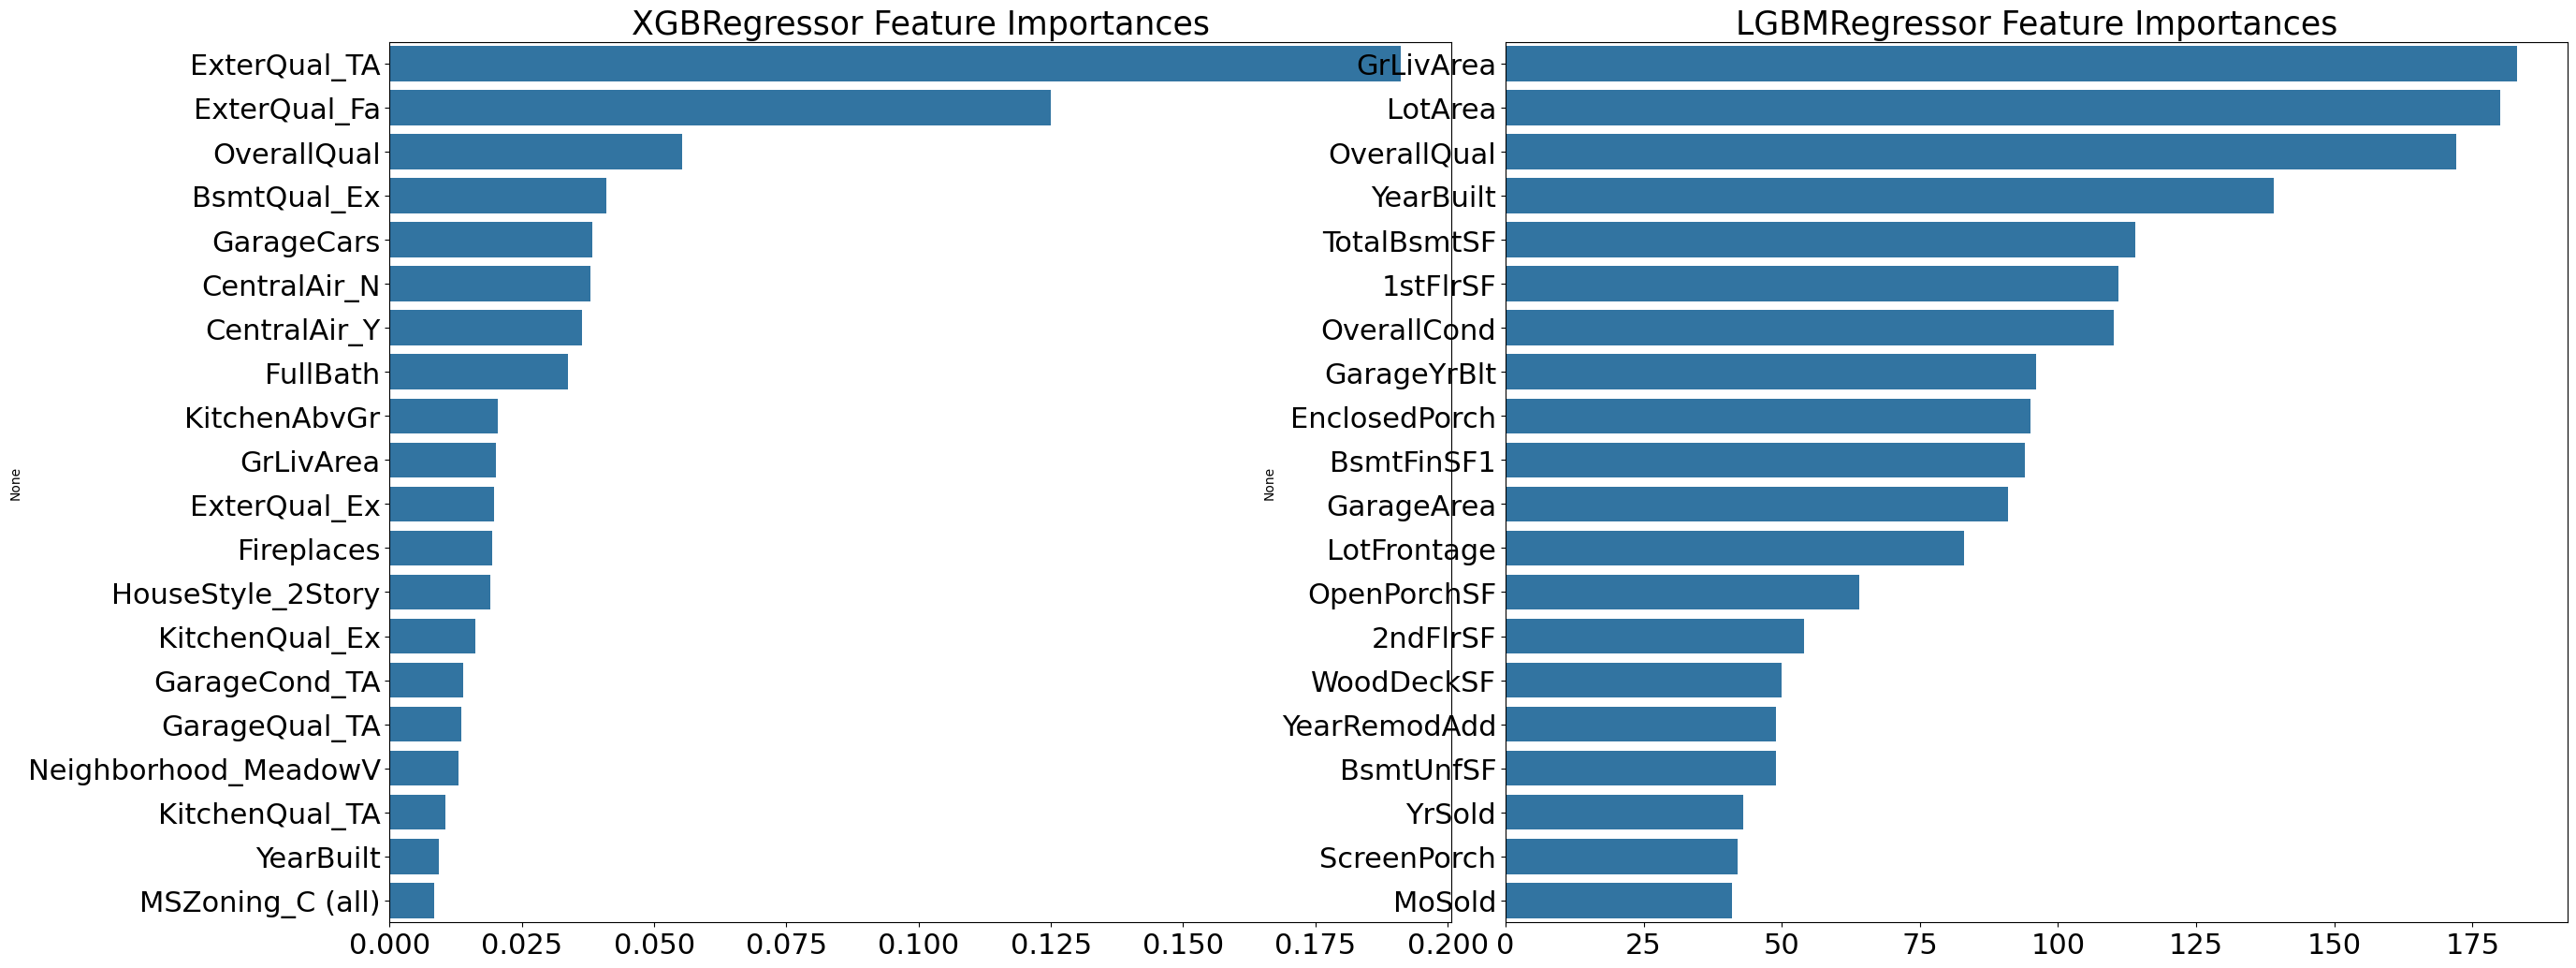

In [40]:
# 모델의 중요도 상위 20개의 피처명과 그때의 중요도값을 Series로 반환
def get_top_features(model):
  ftr_importances_values = model.feature_importances_
  ftr_importances = pd.Series(ftr_importances_values, index=X_features.columns)
  ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]
  return ftr_top20

def visualize_ftr_importances(models):
  # 2개 회귀 모델의 시각화를 위해 2개의 칼럼을 가지는 subplot 생성
  fig, axs = plt.subplots(figsize=(24, 10), nrows=1, ncols=2)
  fig.tight_layout()
  # 입력 인자로 받은 list 객체인 models에서 차례로 model을 추출해 피처 중요도 시각화
  for i_num, model in enumerate(models):
    # 중요도 상위 20개의 피처명과 그때의 중요도값 추출
    ftr_top20 = get_top_features(model)
    axs[i_num].set_title(model.__class__.__name__ + ' Feature Importances', size=25)
    # font 크기 조정
    for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
      label.set_fontsize(22)
    sns.barplot(x=ftr_top20.values, y=ftr_top20.index, ax=axs[i_num])

# 앞 예제에서 print_best_params()가 반환한 GridSearchCV로 최적화된 모델의 피처 중요도 시각화
models = [best_xgb, best_lgbm]
visualize_ftr_importances(models)

#회귀 모델의 예측 결과 혼합을 통한 최종 예측
- 여러 회귀 모델의 예측값에 가중치를 곱해서 더하는 방식으로 최종 예측값을 만들 수 있음
-> ex) A 모델 예측값 x 0.4 + B 모델 예측값 x 0.6 = 최종 예측값
- 가중치에 정해진 기준은 없고, 보통 성능이 더 좋은 모델에 가중치를 더 줌
- 먼저 Ridge와 Lasso를 혼합해 보고, 다음으로 XGBoost와 LightGBM을 혼합해 봄

In [41]:
def get_rmse_pred(preds):
  for key in preds.keys():
    pred_value = preds[key]
    mse = mean_squared_error(y_test, pred_value)
    rmse = np.sqrt(mse)
    print('{0} 모델의 RMSE: {1}'.format(key, rmse))

# 개별 모델의 학습
ridge_reg = Ridge(alpha=8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)
# 개별 모델 예측
ridge_pred = ridge_reg.predict(X_test)
lasso_pred = lasso_reg.predict(X_test)

# 개별 모델 예측값 혼합으로 최종 예측값 도출
pred = 0.4 * ridge_pred + 0.6 * lasso_pred
preds = {'최종 혼합': pred,
         'Ridge': ridge_pred,
         'Lasso': lasso_pred}
# 최종 혼합 모델, 개별 모델의 RMSE 값 출력
get_rmse_pred(preds)

최종 혼합 모델의 RMSE: 0.10006075517615193
Ridge 모델의 RMSE: 0.10340697165289348
Lasso 모델의 RMSE: 0.10024171179335342


In [42]:
xgb_reg = XGBRegressor(n_estimators=1000, learning_rate=0.05,
                       colsample_bytree=0.5, subsample=0.8)
lgbm_reg = LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=4,
                         subsample=0.6, colsample_bytree=0.4, reg_lambda=10, n_jobs=-1, verbose=-1)
xgb_reg.fit(X_train, y_train)
lgbm_reg.fit(X_train, y_train)
xgb_pred = xgb_reg.predict(X_test)
lgbm_pred = lgbm_reg.predict(X_test)

pred = 0.5 * xgb_pred + 0.5 * lgbm_pred
preds = {'최종 혼합': pred,
         'XGBM': xgb_pred,
         'LGBM': lgbm_pred}

get_rmse_pred(preds)

최종 혼합 모델의 RMSE: 0.09967390500680229
XGBM 모델의 RMSE: 0.10309707326102836
LGBM 모델의 RMSE: 0.10363891833477148


- 두 경우 모두 혼합한 최종 예측의 RMSE가 개별 모델보다 조금 더 낮게 나옴

#스태킹 앙상블 모델을 통한 회귀 예측
- 스태킹: 여러 개별 모델(기반 모델)의 예측값을 모아서 새로운 학습 데이터로 만들고, 이걸로 최종 메타 모델을 학습시키는 방식
- 개별 모델이 학습 데이터로 그대로 예측한 값을 쓰면 과적합되기 쉬우므로, KFold로 나눠서 학습에 안 쓴 폴드에 대해서만 예측한 값을 모아 메타 모델용 학습 데이터를 만듦
- 테스트 데이터도 폴드마다 예측한 값을 평균 내서 메타 모델용 테스트 데이터로 사용
- 기반 모델: Ridge, Lasso, XGBoost, LightGBM / 최종 메타 모델: Lasso

In [43]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# 개별 기반 모델에서 최종 메타 모델이 사용할 학습 및 테스트용 데이터를 생성하기 위한 함수
def get_stacking_base_datasets(model, X_train_n, y_train_n, X_test_n, n_folds):
  # 지정된 n_folds 값으로 KFold 생성
  kf = KFold(n_splits=n_folds, shuffle=False)
  # 추후에 메타 모델이 사용할 학습 데이터 반환을 위한 넘파이 배열 초기화
  train_fold_pred = np.zeros((X_train_n.shape[0], 1))
  test_pred = np.zeros((X_test_n.shape[0], n_folds))
  print(model.__class__.__name__, ' model 시작 ')

  for folder_counter, (train_index, valid_index) in enumerate(kf.split(X_train_n)):
    # 입력된 학습 데이터에서 기반 모델이 학습/예측할 폴드 데이터 세트 추출
    print('\t 폴드 세트: ', folder_counter, ' 시작 ')
    X_tr = X_train_n[train_index]
    y_tr = y_train_n[train_index]
    X_te = X_train_n[valid_index]

    # 폴드 세트 내부에서 다시 만들어진 학습 데이터로 기반 모델의 학습 수행
    model.fit(X_tr, y_tr)
    # 폴드 세트 내부에서 다시 만들어진 검증 데이터로 기반 모델 예측 후 데이터 저장
    train_fold_pred[valid_index, :] = model.predict(X_te).reshape(-1, 1)
    # 입력된 원본 테스트 데이터를 폴드 세트 내 학습된 기반 모델에서 예측 후 데이터 저장
    test_pred[:, folder_counter] = model.predict(X_test_n)

  # 폴드 세트 내에서 원본 테스트 데이터를 예측한 데이터를 평균하여 테스트 데이터로 생성
  test_pred_mean = np.mean(test_pred, axis=1).reshape(-1, 1)

  # train_fold_pred는 최종 메타 모델이 사용하는 학습 데이터, test_pred_mean은 테스트 데이터
  return train_fold_pred, test_pred_mean

- get_stacking_base_datasets()는 넘파이 ndarray를 입력받으므로 DataFrame을 넘파이 배열로 변환해서 넣어야 함
- 원핫 인코딩된 칼럼(True/False)과 숫자 칼럼이 섞여 있어서 그냥 .values로 바꾸면 object 타입 배열이 됨 -> dtype=float로 지정해서 변환

In [44]:
# get_stacking_base_datasets()은 넘파이 ndarray를 인자로 사용하므로 DataFrame을 넘파이로 변환
X_train_n = X_train.to_numpy(dtype=float)
X_test_n = X_test.to_numpy(dtype=float)
y_train_n = y_train.values

# 각 개별 기반(Base) 모델이 생성한 학습용/테스트용 데이터 반환
ridge_train, ridge_test = get_stacking_base_datasets(ridge_reg, X_train_n, y_train_n, X_test_n, 5)
lasso_train, lasso_test = get_stacking_base_datasets(lasso_reg, X_train_n, y_train_n, X_test_n, 5)
xgb_train, xgb_test = get_stacking_base_datasets(xgb_reg, X_train_n, y_train_n, X_test_n, 5)
lgbm_train, lgbm_test = get_stacking_base_datasets(lgbm_reg, X_train_n, y_train_n, X_test_n, 5)

Ridge  model 시작 
	 폴드 세트:  0  시작 
	 폴드 세트:  1  시작 
	 폴드 세트:  2  시작 
	 폴드 세트:  3  시작 
	 폴드 세트:  4  시작 
Lasso  model 시작 
	 폴드 세트:  0  시작 
	 폴드 세트:  1  시작 
	 폴드 세트:  2  시작 
	 폴드 세트:  3  시작 
	 폴드 세트:  4  시작 
XGBRegressor  model 시작 
	 폴드 세트:  0  시작 
	 폴드 세트:  1  시작 
	 폴드 세트:  2  시작 
	 폴드 세트:  3  시작 
	 폴드 세트:  4  시작 
LGBMRegressor  model 시작 
	 폴드 세트:  0  시작 
	 폴드 세트:  1  시작 
	 폴드 세트:  2  시작 
	 폴드 세트:  3  시작 
	 폴드 세트:  4  시작 


In [45]:
# 개별 모델이 반환한 학습 및 테스트용 데이터 세트를 스태킹 형태로 결합
Stack_final_X_train = np.concatenate((ridge_train, lasso_train,
                                      xgb_train, lgbm_train), axis=1)
Stack_final_X_test = np.concatenate((ridge_test, lasso_test,
                                     xgb_test, lgbm_test), axis=1)

# 최종 메타 모델은 라쏘 모델을 적용
meta_model_lasso = Lasso(alpha=0.0005)

# 개별 모델 예측값을 기반으로 새롭게 만들어진 학습 및 테스트 데이터로 메타 모델 예측 및 RMSE 측정
meta_model_lasso.fit(Stack_final_X_train, y_train)
final = meta_model_lasso.predict(Stack_final_X_test)
mse = mean_squared_error(y_test, final)
rmse = np.sqrt(mse)
print('스태킹 회귀 모델의 최종 RMSE 값은:', rmse)

스태킹 회귀 모델의 최종 RMSE 값은: 0.09663398093186237


- 스태킹 회귀 모델의 최종 RMSE가 지금까지 만든 모델 중 가장 낮게 나옴
-> 스태킹 모델은 분류뿐 아니라 회귀에서도 효과적으로 사용될 수 있음